[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JaimeHuaytallaPariona/ingenieria-conocimiento-uncp/blob/master/recursos/sesion_02_modelos_clasificacion.ipynb)
# Sesión 02 — Modelos de Clasificación
**Ingeniería del Conocimiento (ISO56B)** · UNCP · 2026-II

**Docente:** Msc. Jaime Antonio Huaytalla Pariona

**Dataset:** Cirrhosis Patient Survival (418 pacientes, 17 features clínicas, clasificación binaria)

**Adaptado a partir del notebook base (Breast Cancer Wisconsin)**, siguiendo exactamente la
misma estructura de secciones, manteniendo las mismas funciones auxiliares y el mismo tipo
de análisis, pero aplicado íntegramente al dataset propio **Cirrhosis** (Mayo Clinic, estudio
de cirrosis biliar primaria), obtenido de Kaggle/UCI.

---

## 1. Configuración del entorno

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, auc,
    ConfusionMatrixDisplay, RocCurveDisplay
)

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

RANDOM_STATE = 42
print('✓ Librerías cargadas correctamente')

✓ Librerías cargadas correctamente


In [ ]:
from google.colab import files

# Esto abrirá un botón para seleccionar y subir el archivo 'cirrhosis.csv' desde tu computadora
uploaded = files.upload()

Saving cirrhosis.csv to cirrhosis.csv


---
## 2. Carga y exploración del dataset

El dataset **Cirrhosis Patient Survival** proviene de un ensayo clínico de la Clínica Mayo
(1974–1984) sobre cirrosis biliar primaria (CBP), una enfermedad hepática crónica. Contiene
**418 pacientes** con **20 columnas**: datos demográficos, síntomas clínicos y resultados de
laboratorio, más la variable `Status` que indica el desenlace de cada paciente al final del
seguimiento:

- **C** — vivo (censurado) al finalizar el estudio
- **CL** — vivo tras un trasplante de hígado
- **D** — falleció durante el estudio

**Adaptación del problema a clasificación binaria** (análoga a maligno/benigno en el ejemplo
base): se define el target **`Fallecio`** = 1 si `Status == 'D'`, y 0 en caso contrario
(agrupando "vivo" y "trasplantado" como el desenlace favorable). Esta es la variable de
interés clínico prioritario, igual que "maligno" lo era en el dataset de cáncer de mama.

In [ ]:
df_raw = pd.read_csv('cirrhosis.csv')

print(f'Dataset: {df_raw.shape[0]} pacientes, {df_raw.shape[1]} columnas')
print(f'\nDistribución de Status (variable original):')
print(df_raw['Status'].value_counts())

df = df_raw.copy()
df['Age_years'] = (df['Age'] / 365.25).round(1)          # Age venía en días
df['Fallecio'] = (df['Status'] == 'D').astype(int)        # Target binario
df['desenlace'] = df['Fallecio'].map({0: 'No falleció', 1: 'Falleció'})

print(f'\nDistribución de clases (target binario):')
print(df['desenlace'].value_counts())
print(f'\nProporción: {df["Fallecio"].mean():.1%} falleció, {1-df["Fallecio"].mean():.1%} no falleció')

Dataset: 418 pacientes, 20 columnas

Distribución de Status (variable original):
Status
C     232
D     161
CL     25
Name: count, dtype: int64

Distribución de clases (target binario):
desenlace
No falleció    257
Falleció       161
Name: count, dtype: int64

Proporción: 38.5% falleció, 61.5% no falleció


In [ ]:
df.describe().round(3)

,ID,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Age_years,Fallecio
count,418.00,418.000,418.000,418.000,284.000,418.000,310.000,312.000,312.000,282.000,407.000,416.000,412.000,418.000,418.000
mean,209.50,1917.782,18533.352,3.221,369.511,3.497,97.648,1982.656,122.556,124.702,257.025,10.732,3.024,50.744,0.385
std,120.81,1104.673,3815.845,4.408,231.945,0.425,85.614,2140.389,56.700,65.149,98.326,1.022,0.882,10.445,0.487
min,1.00,41.000,9598.000,0.300,120.000,1.960,4.000,289.000,26.350,33.000,62.000,9.000,1.000,26.300,0.000
25%,105.25,1092.750,15644.500,0.800,249.500,3.242,41.250,871.500,80.600,84.250,188.500,10.000,2.000,42.850,0.000
50%,209.50,1730.000,18628.000,1.400,309.500,3.530,73.000,1259.000,114.700,108.000,251.000,10.600,3.000,51.000,0.000
75%,313.75,2613.500,21272.500,3.400,400.000,3.770,123.000,1980.000,151.900,151.000,318.000,11.100,4.000,58.275,1.000
max,418.00,4795.000,28650.000,28.000,1775.000,4.640,588.000,13862.400,457.250,598.000,721.000,18.000,4.000,78.400,1.000


In [ ]:
# Estructura y valores faltantes (a diferencia de Breast Cancer, este dataset SÍ tiene NaNs)
print('Valores nulos por columna:')
print(df_raw.isna().sum().sort_values(ascending=False))

print('\n-> "Drug", "Ascites", "Hepatomegaly" y "Spiders" comparten ~106 valores')
print('   faltantes: corresponden a pacientes que fueron registrados en el estudio')
print('   pero no participaron en el ensayo doble-ciego (no se les asignó fármaco),')
print('   por lo que tampoco se les tomaron esas evaluaciones clínicas específicas.')
print('   La ausencia en sí misma es informativa, así que se codificará como una')
print('   categoría explícita ("Desconocido") en vez de imputarla con la moda.')

Valores nulos por columna:
Tryglicerides    136
Cholesterol      134
Copper           108
Drug             106
Alk_Phos         106
SGOT             106
Spiders          106
Hepatomegaly     106
Ascites          106
Platelets         11
Stage              6
Prothrombin        2
Status             0
N_Days             0
ID                 0
Age                0
Bilirubin          0
Edema              0
Sex                0
Albumin            0
dtype: int64

-> "Drug", "Ascites", "Hepatomegaly" y "Spiders" comparten ~106 valores
   faltantes: corresponden a pacientes que fueron registrados en el estudio
   pero no participaron en el ensayo doble-ciego (no se les asignó fármaco),
   por lo que tampoco se les tomaron esas evaluaciones clínicas específicas.
   La ausencia en sí misma es informativa, así que se codificará como una
   categoría explícita ("Desconocido") en vez de imputarla con la moda.


---
## 3. Análisis exploratorio orientado a clasificación

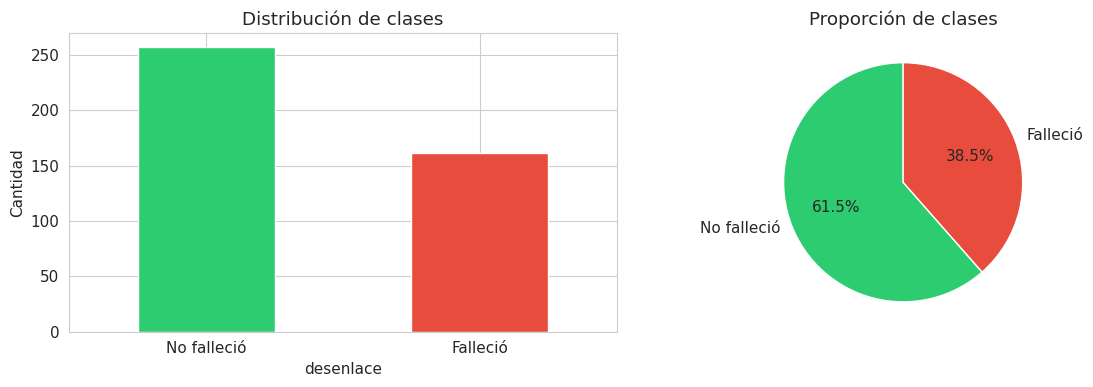

In [ ]:
# 3.1  Distribución de clases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

colors = ['#2ecc71', '#e74c3c']  # No falleció, Falleció
df['desenlace'].value_counts().reindex(['No falleció', 'Falleció']).plot(
    kind='bar', ax=axes[0], color=colors)
axes[0].set_title('Distribución de clases')
axes[0].set_ylabel('Cantidad')
axes[0].set_xticklabels(['No falleció', 'Falleció'], rotation=0)

df['desenlace'].value_counts().reindex(['No falleció', 'Falleció']).plot(
    kind='pie', ax=axes[1], colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_ylabel('')
axes[1].set_title('Proporción de clases')

plt.tight_layout()
plt.show()

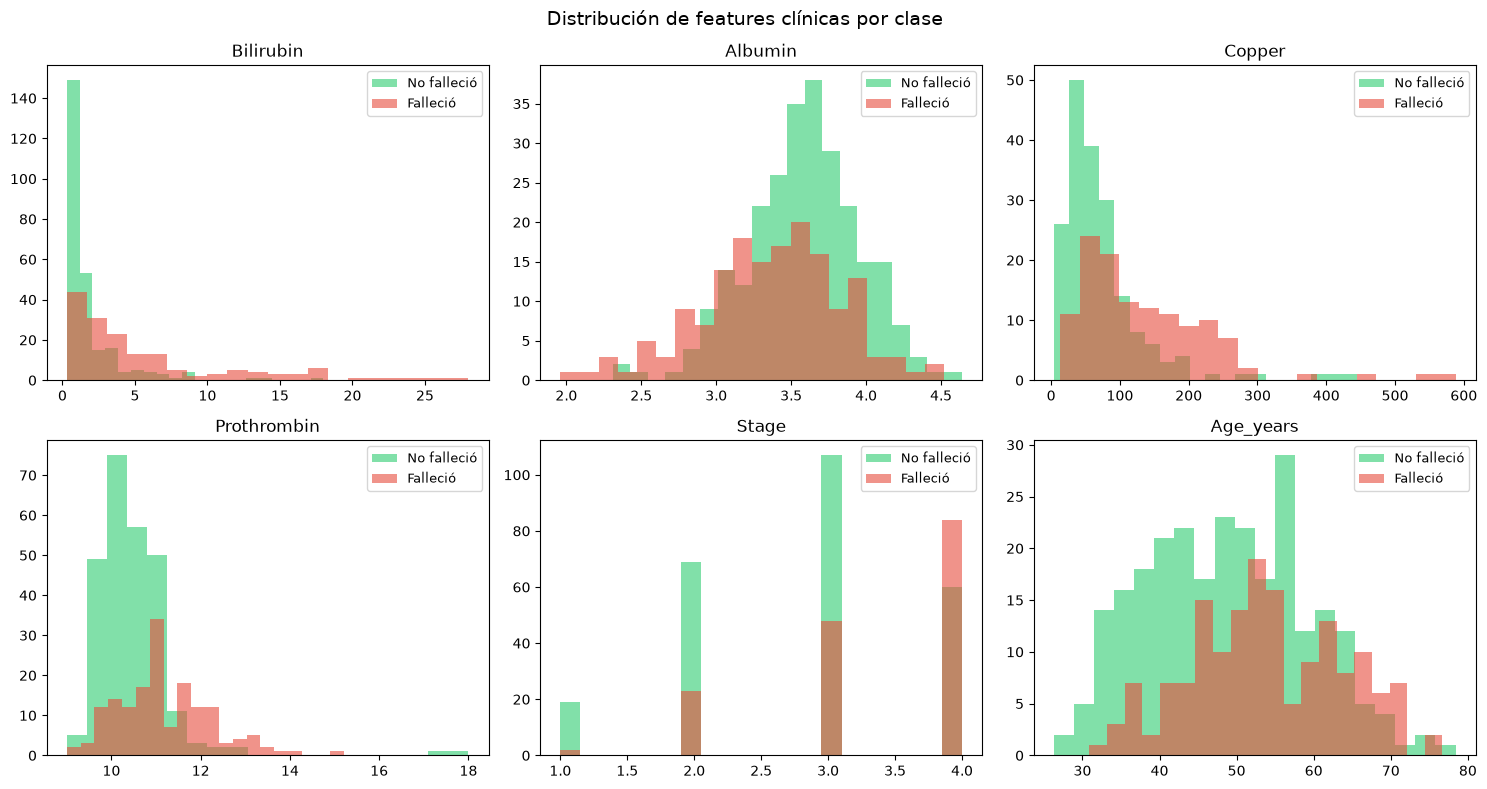

Bilirrubina y Cobre suelen estar elevados, y Albúmina reducida, en los casos
que terminan en fallecimiento: son marcadores clásicos de severidad hepática.


In [ ]:
# 3.2  Distribución de features clave por clase
key_features = ['Bilirubin', 'Albumin', 'Copper', 'Prothrombin', 'Stage', 'Age_years']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, feat in enumerate(key_features):
    ax = axes[i // 3, i % 3]
    for label, color in zip([0, 1], colors):
        subset = df[df['Fallecio'] == label][feat].dropna()
        ax.hist(subset, bins=20, alpha=0.6, color=color,
                label='No falleció' if label == 0 else 'Falleció')
    ax.set_title(feat)
    ax.legend(fontsize=9)

plt.suptitle('Distribución de features clínicas por clase', fontsize=14)
plt.tight_layout()
plt.show()

print('Bilirrubina y Cobre suelen estar elevados, y Albúmina reducida, en los casos')
print('que terminan en fallecimiento: son marcadores clásicos de severidad hepática.')

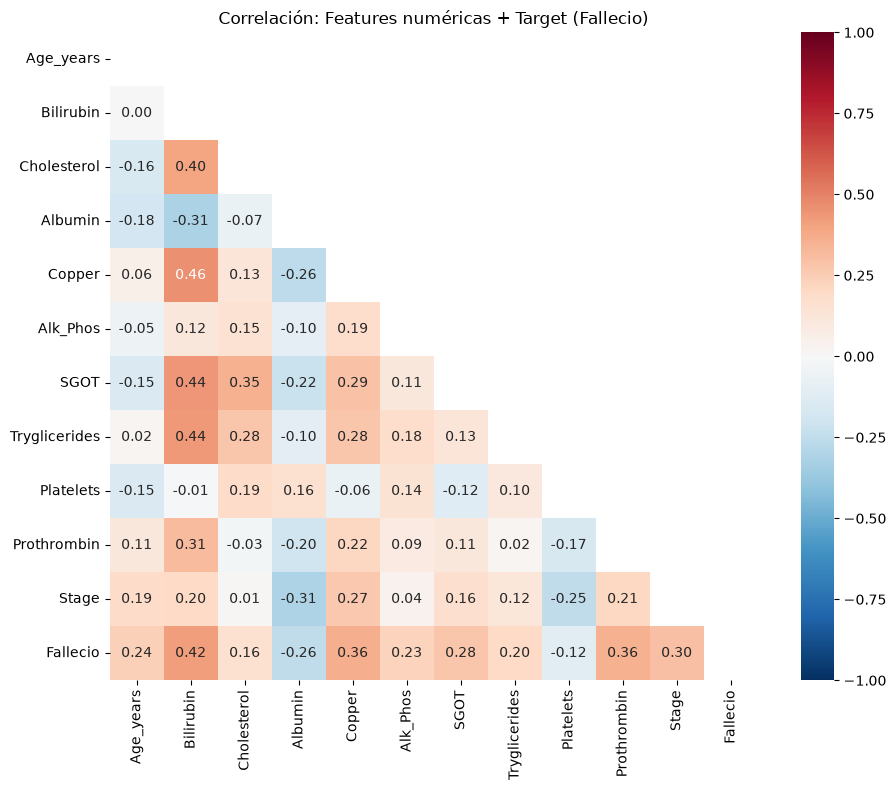

In [ ]:
# 3.3  Matriz de correlación (features numéricas + target)
NUM_FEATURES = ['Age_years', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
                'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']

plt.figure(figsize=(10, 8))
corr = df[NUM_FEATURES + ['Fallecio']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True)
plt.title('Correlación: Features numéricas + Target (Fallecio)')
plt.tight_layout()
plt.show()

Los pacientes que fallecen tienden a concentrarse en la zona de bilirrubina alta
y albúmina baja, coherente con la fisiopatología de la insuficiencia hepática.


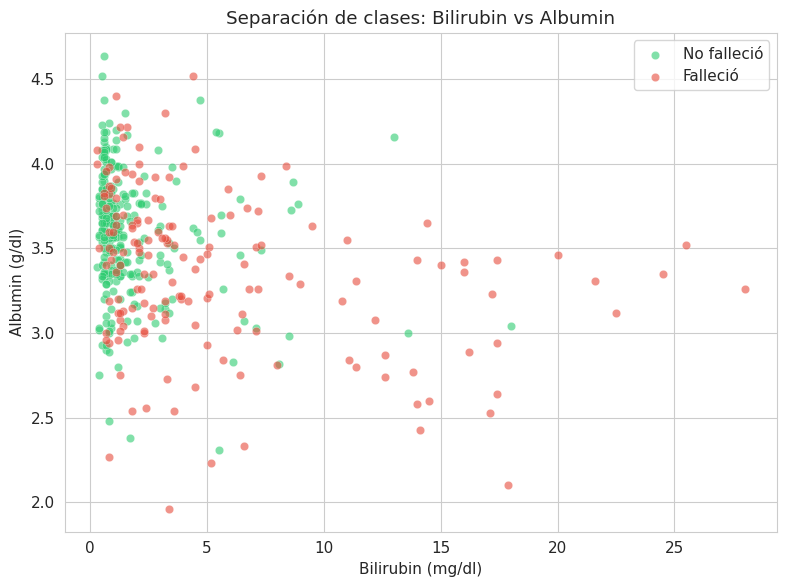

In [ ]:
# 3.4  Scatter plot: 2 features más discriminativas (marcadores clásicos de cirrosis)
fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in zip([0, 1], colors, ['No falleció', 'Falleció']):
    mask = df['Fallecio'] == label
    ax.scatter(df.loc[mask, 'Bilirubin'], df.loc[mask, 'Albumin'],
               alpha=0.6, c=color, label=name, edgecolors='w', linewidth=0.3)
ax.set_xlabel('Bilirubin (mg/dl)')
ax.set_ylabel('Albumin (g/dl)')
ax.set_title('Separación de clases: Bilirubin vs Albumin')
ax.legend()
plt.tight_layout()
plt.show()

print('Los pacientes que fallecen tienden a concentrarse en la zona de bilirrubina alta')
print('y albúmina baja, coherente con la fisiopatología de la insuficiencia hepática.')

---
## 4. Preparación de datos

In [ ]:
NUMERIC_COLS = ['Age_years', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
                'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']
CATEGORICAL_COLS = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']

# 'ID' se descarta (identificador, no informativo) y 'N_Days' se descarta a propósito:
# es el número de días hasta el desenlace (muerte/trasplante/fin de estudio), por lo
# que está directamente ligado al target y usarlo sería una fuga de datos (data leakage)
# -- en la práctica clínica real, N_Days NO se conoce de antemano para un paciente nuevo.

X = df[NUMERIC_COLS + CATEGORICAL_COLS].copy()
y = df['Fallecio'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'Entrenamiento: {X_train.shape[0]} pacientes')
print(f'Test:          {X_test.shape[0]} pacientes')
print(f'\nProporción en train: {y_train.mean():.1%} falleció')
print(f'Proporción en test:  {y_test.mean():.1%} falleció')

# Stratified K-Fold para validación cruzada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: 334 pacientes
Test:          84 pacientes

Proporción en train: 38.6% falleció
Proporción en test:  38.1% falleció


In [ ]:
# Preprocesamiento común: imputación + codificación (+ escalado cuando aplica).
# A diferencia de Breast Cancer (sin NaNs y 100% numérico), aquí es indispensable
# manejar valores faltantes y variables categóricas antes de entrenar cualquier modelo.
preprocess_scaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), NUMERIC_COLS),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Desconocido')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), CATEGORICAL_COLS),
])

# Para el Árbol de Decisión no es necesario escalar las numéricas
preprocess_tree = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUMERIC_COLS),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Desconocido')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), CATEGORICAL_COLS),
])

print('ColumnTransformer definidos: preprocess_scaled (LR/SVM/KNN) y preprocess_tree (Árbol).')

ColumnTransformer definidos: preprocess_scaled (LR/SVM/KNN) y preprocess_tree (Árbol).


### Funciones auxiliares para evaluación de clasificadores

In [ ]:
def eval_classifier(model, X_tr, y_tr, X_te, y_te, model_name='Modelo'):
    '''Evalúa un clasificador: métricas, matriz de confusión y reporte.'''
    y_pred = model.predict(X_te)

    metrics = {
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall':    recall_score(y_te, y_pred),
        'F1-Score':  f1_score(y_te, y_pred)
    }

    print(f'=== {model_name} ===')
    for k, v in metrics.items():
        print(f'  {k}: {v:.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['No falleció', 'Falleció'],
                yticklabels=['No falleció', 'Falleció'])
    axes[0].set_title(f'Matriz de Confusión — {model_name}')
    axes[0].set_xlabel('Predicción')
    axes[0].set_ylabel('Real')

    tn, fp, fn, tp = cm.ravel()
    labels = ['TN\n(no falleció\ncorrecto)', 'FP\n(no falleció→\nfalleció)',
              'FN\n(falleció→\nno falleció)', 'TP\n(falleció\ncorrecto)']
    values = [tn, fp, fn, tp]
    bar_colors = ['#2ecc71', '#f39c12', '#e74c3c', '#3498db']
    axes[1].bar(labels, values, color=bar_colors)
    axes[1].set_title(f'Desglose — {model_name}')
    axes[1].set_ylabel('Cantidad')

    plt.tight_layout()
    plt.show()

    print(f'\n  FN (muerte NO detectada, la más grave clínicamente): {fn}')
    print(f'  FP (falsa alarma de fallecimiento): {fp}')
    print(f'\nReporte completo:')
    print(classification_report(y_te, y_pred,
          target_names=['No falleció', 'Falleció']))

    return metrics


def plot_roc(model, X_te, y_te, model_name='Modelo', ax=None):
    '''Genera la curva ROC de un modelo.'''
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_te)
    else:
        print(f'{model_name}: no soporta probabilidades')
        return None

    fpr, tpr, _ = roc_curve(y_te, y_score)
    roc_auc = auc(fpr, tpr)

    ax.plot(fpr, tpr, linewidth=2,
            label=f'{model_name} (AUC = {roc_auc:.4f})')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
    ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
    ax.set_title(f'Curva ROC — {model_name}')
    ax.legend()

    return roc_auc

print('Funciones auxiliares definidas: eval_classifier(), plot_roc()')

Funciones auxiliares definidas: eval_classifier(), plot_roc()


---
## 5. Modelo 1 — Regresión Logística

**Fundamento:** Modelo lineal que estima P(y=1|x) mediante la función sigmoide σ(z) = 1/(1+e^(−z)). La frontera de decisión es lineal en el espacio de features. Se optimiza minimizando la Log-Loss (entropía cruzada binaria) con regularización L2 por defecto.

In [ ]:
# 5.1  Pipeline con imputación + escalado
pipe_lr = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

cv_lr = cross_validate(pipe_lr, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Regresión Logística — Cross-Validation (5-fold)')
print(f'  Accuracy:  {cv_lr["test_accuracy"].mean():.4f} ± {cv_lr["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_lr["test_f1"].mean():.4f} ± {cv_lr["test_f1"].std():.4f}')
print(f'  Recall:    {cv_lr["test_recall"].mean():.4f} ± {cv_lr["test_recall"].std():.4f}')

pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

Regresión Logística — Cross-Validation (5-fold)
  Accuracy:  0.7426 ± 0.0796
  F1-Score:  0.6261 ± 0.1228
  Recall:    0.5662 ± 0.1264


=== Regresión Logística ===
  Accuracy: 0.8571
  Precision: 0.8846
  Recall: 0.7188
  F1-Score: 0.7931

  FN (muerte NO detectada, la más grave clínicamente): 9
  FP (falsa alarma de fallecimiento): 3

Reporte completo:
              precision    recall  f1-score   support

 No falleció       0.84      0.94      0.89        52
    Falleció       0.88      0.72      0.79        32

    accuracy                           0.86        84
   macro avg       0.86      0.83      0.84        84
weighted avg       0.86      0.86      0.85        84



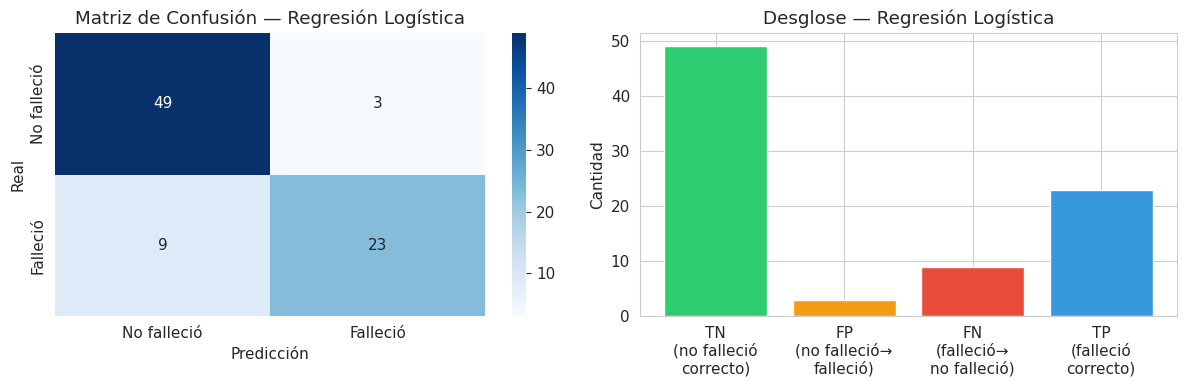

In [ ]:
# 5.2  Evaluación completa
metrics_lr = eval_classifier(pipe_lr, X_train, y_train, X_test, y_test,
                             'Regresión Logística')

Interpretación:
  → Features que más indican "No falleció": ['cat__Ascites_N', 'cat__Edema_N', 'cat__Sex_F']
  → Features que más indican "Falleció":    ['num__Age_years', 'cat__Ascites_Y', 'num__Bilirubin']


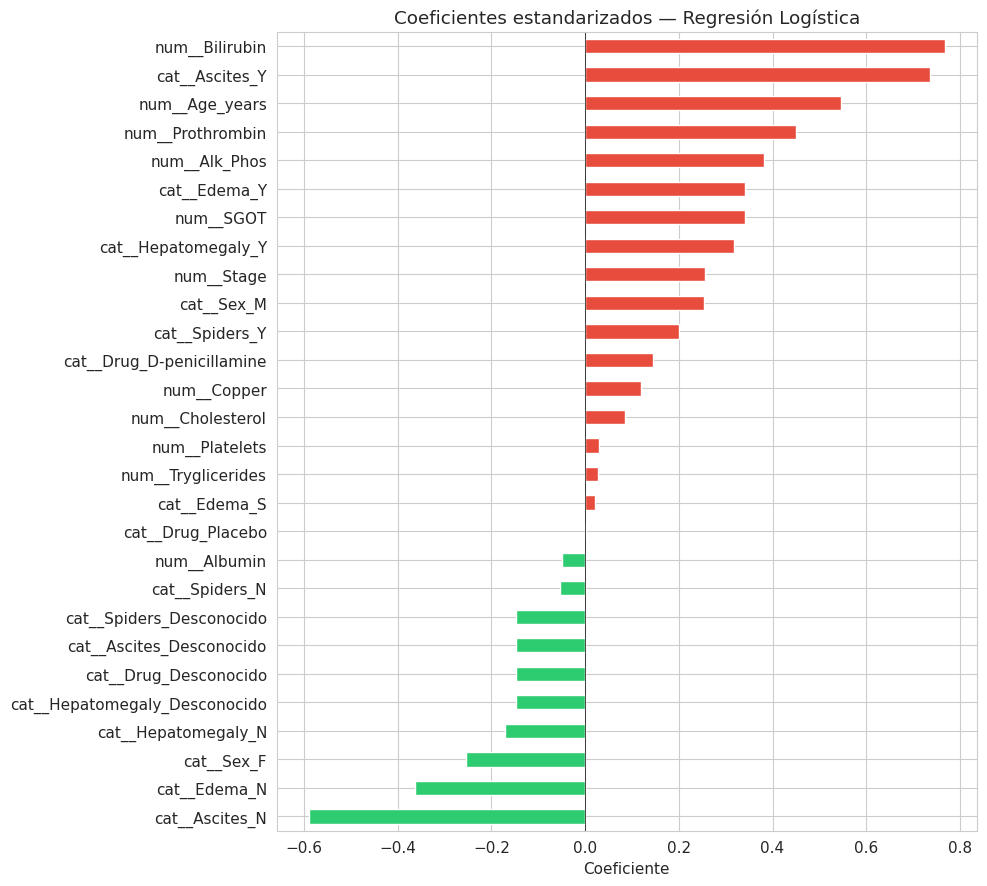

In [ ]:
# 5.3  Coeficientes estandarizados
feature_names = pipe_lr.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(
    pipe_lr.named_steps['clf'].coef_[0],
    index=feature_names
).sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
colors_bar = ['#2ecc71' if c < 0 else '#e74c3c' for c in coefs]
coefs.plot(kind='barh', ax=ax, color=colors_bar)
ax.set_title('Coeficientes estandarizados — Regresión Logística')
ax.set_xlabel('Coeficiente')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

print('Interpretación:')
print(f'  → Features que más indican "No falleció": {coefs.head(3).index.tolist()}')
print(f'  → Features que más indican "Falleció":    {coefs.tail(3).index.tolist()}')

AUC: 0.8918


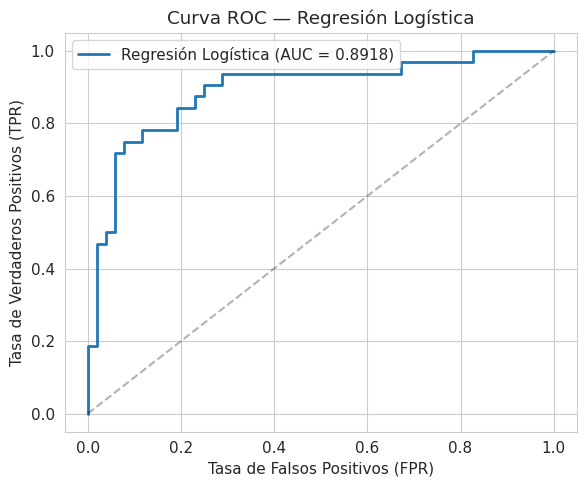

In [ ]:
# 5.4  Curva ROC
fig, ax = plt.subplots(figsize=(6, 5))
auc_lr = plot_roc(pipe_lr, X_test, y_test, 'Regresión Logística', ax)
plt.tight_layout()
plt.show()
print(f'AUC: {auc_lr:.4f}')

---
## 6. Modelo 2 — Árbol de Decisión

**Fundamento:** CART construye particiones recursivas del espacio de features. En cada nodo selecciona la feature y el umbral que maximizan la reducción de impureza (Gini: G(t) = 1 − Σpₖ²). Las particiones son ortogonales a los ejes.

In [ ]:
# 6.1  Árbol sin restricciones (para mostrar sobreajuste)
pipe_dt_full = Pipeline([
    ('pre', preprocess_tree),
    ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

cv_dt_full = cross_validate(pipe_dt_full, X_train, y_train, cv=skf,
                            scoring=['accuracy', 'f1', 'recall'],
                            return_train_score=True)

print('Árbol de Decisión (SIN restricciones) — CV 5-fold')
print(f'  Train Accuracy: {cv_dt_full["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_dt_full["test_accuracy"].mean():.4f} ± {cv_dt_full["test_accuracy"].std():.4f}')
print(f'  Test F1-Score:  {cv_dt_full["test_f1"].mean():.4f} ± {cv_dt_full["test_f1"].std():.4f}')
print(f'\n⚠ Train accuracy ~1.0 indica sobreajuste')

Árbol de Decisión (SIN restricciones) — CV 5-fold
  Train Accuracy: 1.0000
  Test Accuracy:  0.6379 ± 0.0670
  Test F1-Score:  0.5367 ± 0.0958

⚠ Train accuracy ~1.0 indica sobreajuste


In [ ]:
# 6.2  Árbol con pre-poda
pipe_dt = Pipeline([
    ('pre', preprocess_tree),
    ('clf', DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    ))
])

cv_dt = cross_validate(pipe_dt, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Árbol de Decisión (con pre-poda) — CV 5-fold')
print(f'  Train Accuracy: {cv_dt["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_dt["test_accuracy"].mean():.4f} ± {cv_dt["test_accuracy"].std():.4f}')
print(f'  Test F1-Score:  {cv_dt["test_f1"].mean():.4f} ± {cv_dt["test_f1"].std():.4f}')
print(f'  Test Recall:    {cv_dt["test_recall"].mean():.4f} ± {cv_dt["test_recall"].std():.4f}')

pipe_dt.fit(X_train, y_train)
y_pred_dt = pipe_dt.predict(X_test)

Árbol de Decisión (con pre-poda) — CV 5-fold
  Train Accuracy: 0.8555
  Test Accuracy:  0.6646 ± 0.0727
  Test F1-Score:  0.5331 ± 0.1124
  Test Recall:    0.5043 ± 0.1257


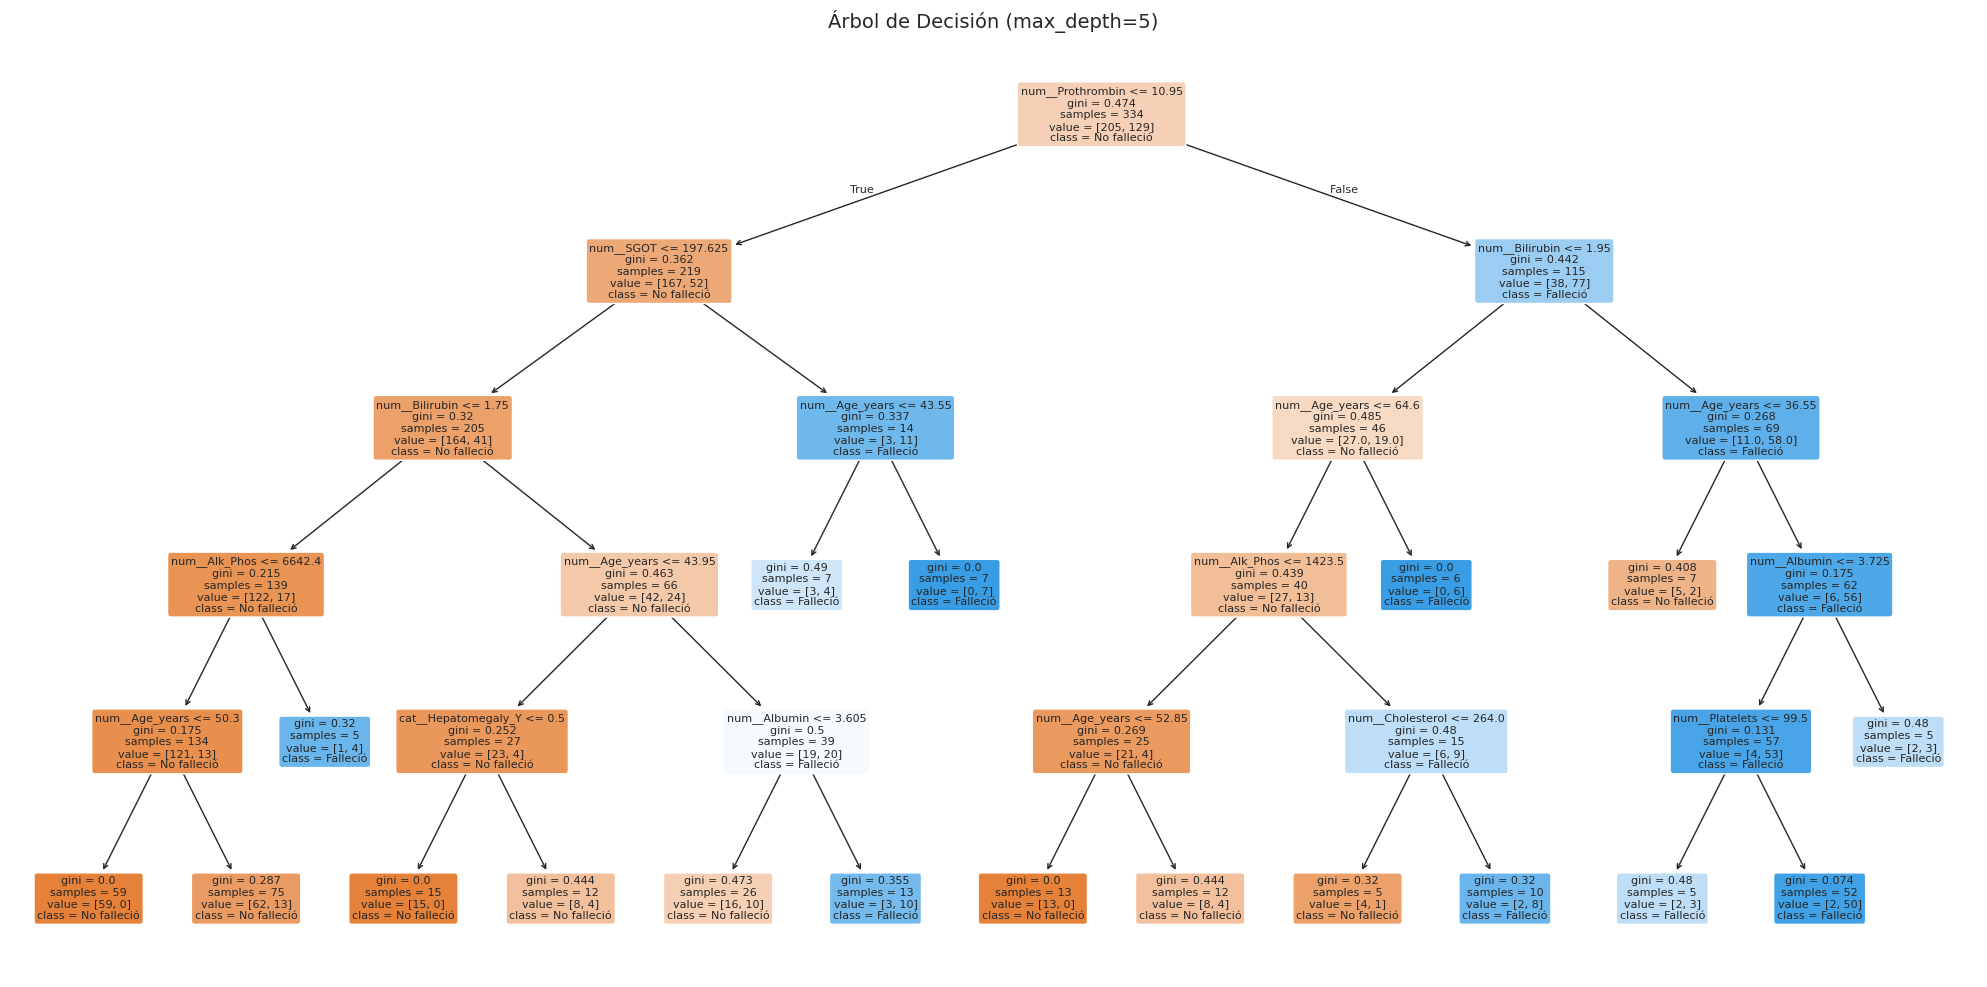

In [ ]:
# 6.3  Visualización del árbol podado
feature_names_tree = pipe_dt.named_steps['pre'].get_feature_names_out()

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(pipe_dt.named_steps['clf'],
          feature_names=list(feature_names_tree),
          class_names=['No falleció', 'Falleció'],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Árbol de Decisión (max_depth=5)', fontsize=14)
plt.tight_layout()
plt.show()

=== Árbol de Decisión ===
  Accuracy: 0.8571
  Precision: 0.9167
  Recall: 0.6875
  F1-Score: 0.7857

  FN (muerte NO detectada, la más grave clínicamente): 10
  FP (falsa alarma de fallecimiento): 2

Reporte completo:
              precision    recall  f1-score   support

 No falleció       0.83      0.96      0.89        52
    Falleció       0.92      0.69      0.79        32

    accuracy                           0.86        84
   macro avg       0.88      0.82      0.84        84
weighted avg       0.87      0.86      0.85        84



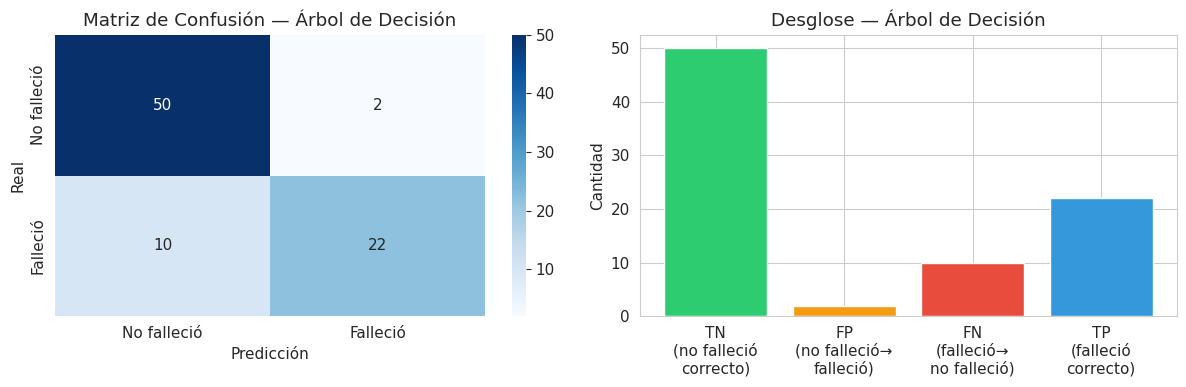

In [ ]:
# 6.4  Evaluación completa
metrics_dt = eval_classifier(pipe_dt, X_train, y_train, X_test, y_test,
                             'Árbol de Decisión')

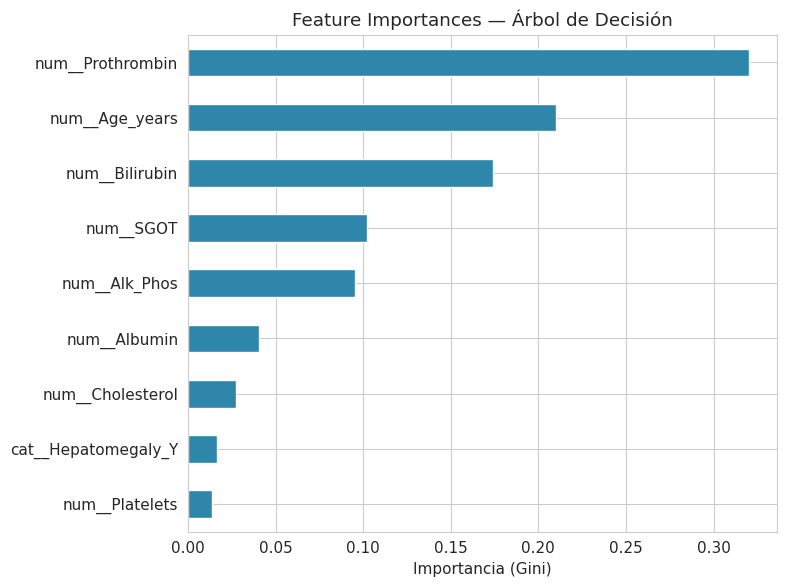

In [ ]:
# 6.5  Importancia de features
importances = pd.Series(
    pipe_dt.named_steps['clf'].feature_importances_,
    index=feature_names_tree
).sort_values(ascending=True)
importances = importances[importances > 0]

fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind='barh', ax=ax, color='#2E86AB')
ax.set_title('Feature Importances — Árbol de Decisión')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.show()

Mejor ccp_alpha: 0.026921


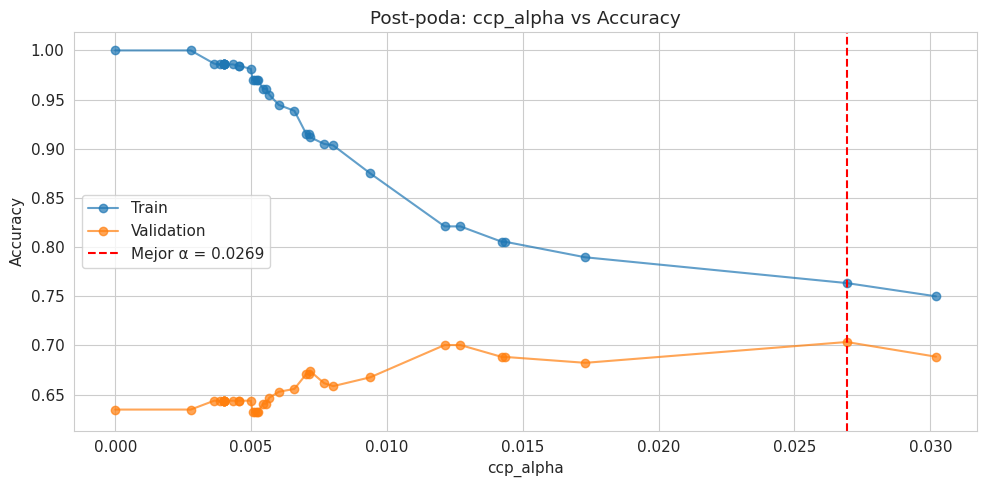

In [ ]:
# 6.6  Post-poda con ccp_alpha
X_train_tree = pipe_dt.named_steps['pre'].fit_transform(X_train, y_train)

path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X_train_tree, y_train)
alphas = path.ccp_alphas[:-1]  # excluir el último (árbol trivial)

train_scores, test_scores = [], []
for alpha in alphas:
    dt_temp = DecisionTreeClassifier(ccp_alpha=alpha, random_state=RANDOM_STATE)
    cv_temp = cross_validate(dt_temp, X_train_tree, y_train, cv=skf,
                             scoring='accuracy', return_train_score=True)
    train_scores.append(cv_temp['train_score'].mean())
    test_scores.append(cv_temp['test_score'].mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(alphas, train_scores, 'o-', label='Train', alpha=0.7)
ax.plot(alphas, test_scores, 'o-', label='Validation', alpha=0.7)
best_idx = np.argmax(test_scores)
ax.axvline(x=alphas[best_idx], color='red', linestyle='--',
           label=f'Mejor α = {alphas[best_idx]:.4f}')
ax.set_xlabel('ccp_alpha')
ax.set_ylabel('Accuracy')
ax.set_title('Post-poda: ccp_alpha vs Accuracy')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Mejor ccp_alpha: {alphas[best_idx]:.6f}')

---
## 7. Modelo 3 — Support Vector Machine (SVM)

**Fundamento:** SVM busca el hiperplano de máximo margen γ = 2/‖w‖ que separa las clases. Con margen suave, permite violaciones controladas: min ½‖w‖² + C·Σξᵢ. El kernel trick transforma el espacio para manejar no linealidad.

In [ ]:
# 7.1  Pipeline SVM con kernel RBF
pipe_svm = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE))
])

cv_svm = cross_validate(pipe_svm, X_train, y_train, cv=skf,
                        scoring=['accuracy', 'f1', 'recall'],
                        return_train_score=True)

print('SVM (RBF, C=1.0) — CV 5-fold')
print(f'  Accuracy:  {cv_svm["test_accuracy"].mean():.4f} ± {cv_svm["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_svm["test_f1"].mean():.4f} ± {cv_svm["test_f1"].std():.4f}')
print(f'  Recall:    {cv_svm["test_recall"].mean():.4f} ± {cv_svm["test_recall"].std():.4f}')

pipe_svm.fit(X_train, y_train)
y_pred_svm = pipe_svm.predict(X_test)

SVM (RBF, C=1.0) — CV 5-fold
  Accuracy:  0.7454 ± 0.0704
  F1-Score:  0.6326 ± 0.1104
  Recall:    0.5812 ± 0.1367


=== SVM (RBF) ===
  Accuracy: 0.8333
  Precision: 0.8214
  Recall: 0.7188
  F1-Score: 0.7667

  FN (muerte NO detectada, la más grave clínicamente): 9
  FP (falsa alarma de fallecimiento): 5

Reporte completo:
              precision    recall  f1-score   support

 No falleció       0.84      0.90      0.87        52
    Falleció       0.82      0.72      0.77        32

    accuracy                           0.83        84
   macro avg       0.83      0.81      0.82        84
weighted avg       0.83      0.83      0.83        84



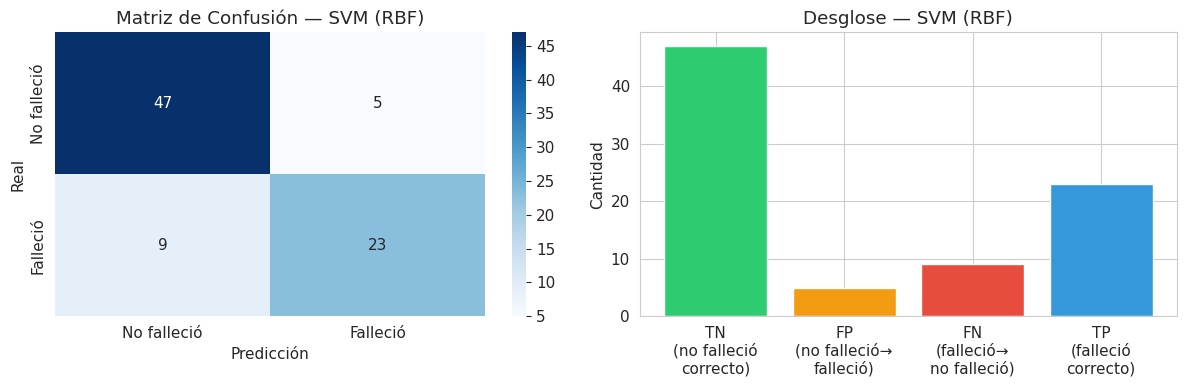

In [ ]:
# 7.2  Evaluación completa
metrics_svm = eval_classifier(pipe_svm, X_train, y_train, X_test, y_test, 'SVM (RBF)')

  Kernel linear  : Accuracy = 0.7276
  Kernel rbf     : Accuracy = 0.7454
  Kernel poly    : Accuracy = 0.7096


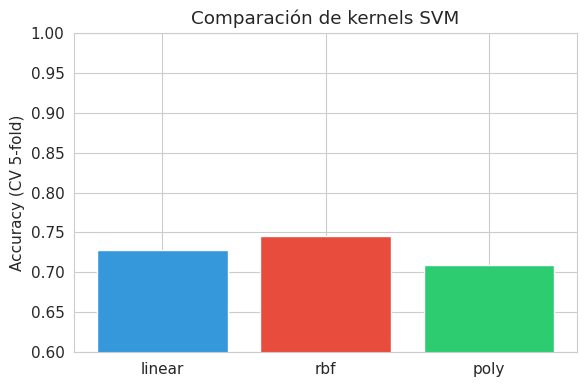

In [ ]:
# 7.3  Comparación de kernels
kernels = ['linear', 'rbf', 'poly']
kernel_results = {}

for k in kernels:
    pipe_k = Pipeline([
        ('pre', preprocess_scaled),
        ('clf', SVC(kernel=k, C=1.0, probability=True, random_state=RANDOM_STATE))
    ])
    cv_k = cross_validate(pipe_k, X_train, y_train, cv=skf, scoring='accuracy')
    kernel_results[k] = cv_k['test_score'].mean()
    print(f'  Kernel {k:8s}: Accuracy = {kernel_results[k]:.4f}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(kernel_results.keys(), kernel_results.values(), color=['#3498db', '#e74c3c', '#2ecc71'])
ax.set_ylabel('Accuracy (CV 5-fold)')
ax.set_title('Comparación de kernels SVM')
ax.set_ylim(0.6, 1.0)
plt.tight_layout()
plt.show()


Interpretación:
  C bajo → margen amplio, más errores permitidos (mayor sesgo)
  C alto → margen estrecho, menos errores permitidos (mayor varianza)


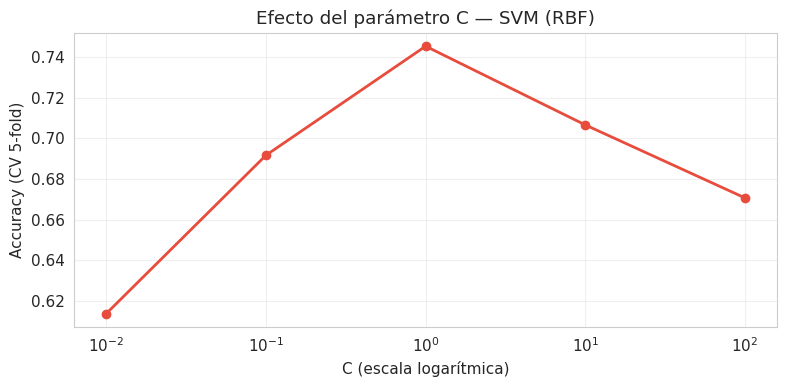

In [ ]:
# 7.4  Efecto del parámetro C
C_values = [0.01, 0.1, 1, 10, 100]
c_scores = []

for c in C_values:
    pipe_c = Pipeline([
        ('pre', preprocess_scaled),
        ('clf', SVC(kernel='rbf', C=c, random_state=RANDOM_STATE))
    ])
    cv_c = cross_validate(pipe_c, X_train, y_train, cv=skf, scoring='accuracy')
    c_scores.append(cv_c['test_score'].mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(C_values, c_scores, 'o-', color='#e74c3c', linewidth=2)
ax.set_xlabel('C (escala logarítmica)')
ax.set_ylabel('Accuracy (CV 5-fold)')
ax.set_title('Efecto del parámetro C — SVM (RBF)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nInterpretación:')
print('  C bajo → margen amplio, más errores permitidos (mayor sesgo)')
print('  C alto → margen estrecho, menos errores permitidos (mayor varianza)')

---
## 8. Modelo 4 — K-Nearest Neighbors (KNN)

**Fundamento:** Algoritmo de aprendizaje basado en instancias (lazy learning). No construye un modelo explícito; clasifica por voto mayoritario de los K vecinos más cercanos según distancia Euclidiana (por defecto). La regla empírica sugiere K ≈ √n.

In [ ]:
# 8.1  Pipeline KNN
pipe_knn = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', KNeighborsClassifier(n_neighbors=5))
])

cv_knn = cross_validate(pipe_knn, X_train, y_train, cv=skf,
                        scoring=['accuracy', 'f1', 'recall'],
                        return_train_score=True)

print('KNN (K=5) — CV 5-fold')
print(f'  Accuracy:  {cv_knn["test_accuracy"].mean():.4f} ± {cv_knn["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_knn["test_f1"].mean():.4f} ± {cv_knn["test_f1"].std():.4f}')
print(f'  Recall:    {cv_knn["test_recall"].mean():.4f} ± {cv_knn["test_recall"].std():.4f}')

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)

KNN (K=5) — CV 5-fold
  Accuracy:  0.7037 ± 0.0266
  F1-Score:  0.5460 ± 0.0547
  Recall:    0.4658 ± 0.0698


=== KNN (K=5) ===
  Accuracy: 0.7738
  Precision: 0.8095
  Recall: 0.5312
  F1-Score: 0.6415

  FN (muerte NO detectada, la más grave clínicamente): 15
  FP (falsa alarma de fallecimiento): 4

Reporte completo:
              precision    recall  f1-score   support

 No falleció       0.76      0.92      0.83        52
    Falleció       0.81      0.53      0.64        32

    accuracy                           0.77        84
   macro avg       0.79      0.73      0.74        84
weighted avg       0.78      0.77      0.76        84



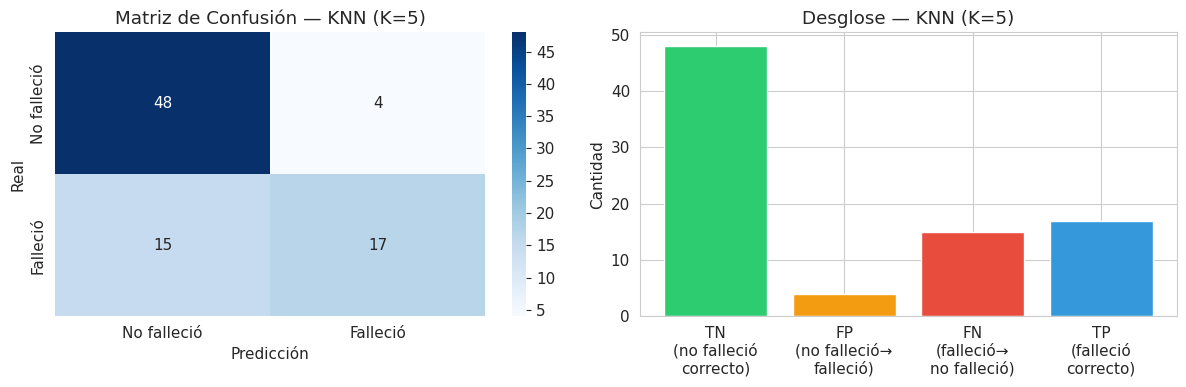

In [ ]:
# 8.2  Evaluación completa
metrics_knn = eval_classifier(pipe_knn, X_train, y_train, X_test, y_test, 'KNN (K=5)')

Mejor K por F1: 3
K empírico (√334): 18


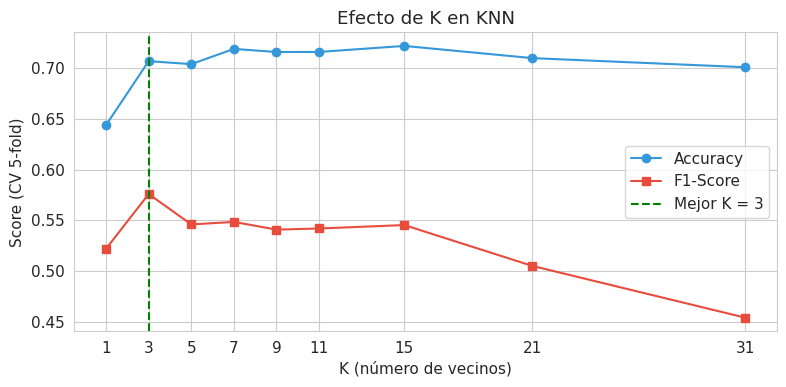

In [ ]:
# 8.3  Búsqueda del K óptimo
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_scores_acc = []
k_scores_f1 = []

for k in k_values:
    pipe_k = Pipeline([
        ('pre', preprocess_scaled),
        ('clf', KNeighborsClassifier(n_neighbors=k))
    ])
    cv_k = cross_validate(pipe_k, X_train, y_train, cv=skf,
                          scoring=['accuracy', 'f1'])
    k_scores_acc.append(cv_k['test_accuracy'].mean())
    k_scores_f1.append(cv_k['test_f1'].mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, k_scores_acc, 'o-', label='Accuracy', color='#3498db')
ax.plot(k_values, k_scores_f1, 's-', label='F1-Score', color='#e74c3c')
best_k = k_values[np.argmax(k_scores_f1)]
ax.axvline(x=best_k, color='green', linestyle='--', label=f'Mejor K = {best_k}')
ax.set_xlabel('K (número de vecinos)')
ax.set_ylabel('Score (CV 5-fold)')
ax.set_title('Efecto de K en KNN')
ax.legend()
ax.set_xticks(k_values)
plt.tight_layout()
plt.show()

print(f'Mejor K por F1: {best_k}')
print(f'K empírico (√{len(X_train)}): {int(np.sqrt(len(X_train)))}')

In [ ]:
# 8.4  Comparación de métricas de distancia
distances = ['euclidean', 'manhattan', 'minkowski']
dist_results = {}

for d in distances:
    p_val = 3 if d == 'minkowski' else 2
    pipe_d = Pipeline([
        ('pre', preprocess_scaled),
        ('clf', KNeighborsClassifier(n_neighbors=5, metric=d, p=p_val))
    ])
    cv_d = cross_validate(pipe_d, X_train, y_train, cv=skf, scoring='f1')
    dist_results[d] = cv_d['test_score'].mean()
    label = f'{d} (p={p_val})' if d == 'minkowski' else d
    print(f'  Distancia {label:20s}: F1 = {dist_results[d]:.4f}')

  Distancia euclidean           : F1 = 0.5460
  Distancia manhattan           : F1 = 0.5492
  Distancia minkowski (p=3)     : F1 = 0.5747


---
## 9. Comparación final de modelos

In [ ]:
# 9.1  Tabla resumen de métricas
all_models = {
    'Regresión Logística': pipe_lr,
    'Árbol de Decisión': pipe_dt,
    'SVM (RBF)': pipe_svm,
    'KNN (K=5)': pipe_knn
}

all_metrics = {}
for name, model in all_models.items():
    y_pred = model.predict(X_test)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc_val = auc(fpr, tpr)
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_test)
        fpr, tpr, _ = roc_curve(y_test, y_score)
        roc_auc_val = auc(fpr, tpr)
    else:
        roc_auc_val = None

    all_metrics[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'AUC': roc_auc_val
    }

metrics_df = pd.DataFrame(all_metrics).T.round(4)
print('=== Tabla comparativa de métricas (Test Set) ===')
metrics_df

=== Tabla comparativa de métricas (Test Set) ===


,Accuracy,Precision,Recall,F1-Score,AUC
Regresión Logística,0.8571,0.8846,0.7188,0.7931,0.8918
Árbol de Decisión,0.8571,0.9167,0.6875,0.7857,0.9111
SVM (RBF),0.8333,0.8214,0.7188,0.7667,0.8636
KNN (K=5),0.7738,0.8095,0.5312,0.6415,0.8080


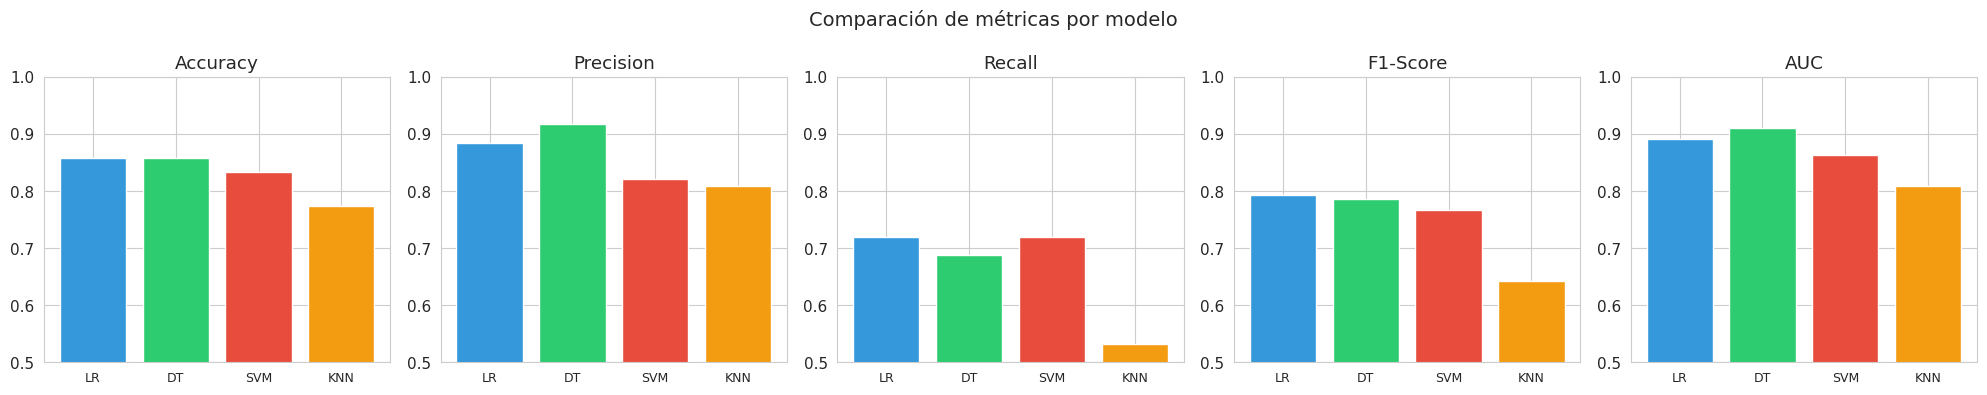

In [ ]:
# 9.2  Gráfico de barras comparativo
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
colors_models = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

for i, metric in enumerate(metric_names):
    values = [all_metrics[m][metric] for m in all_metrics]
    axes[i].bar(range(len(values)), values, color=colors_models)
    axes[i].set_title(metric)
    axes[i].set_ylim(0.5, 1.0)
    axes[i].set_xticks(range(len(values)))
    axes[i].set_xticklabels(['LR', 'DT', 'SVM', 'KNN'], fontsize=9)

plt.suptitle('Comparación de métricas por modelo', fontsize=14)
plt.tight_layout()
plt.show()

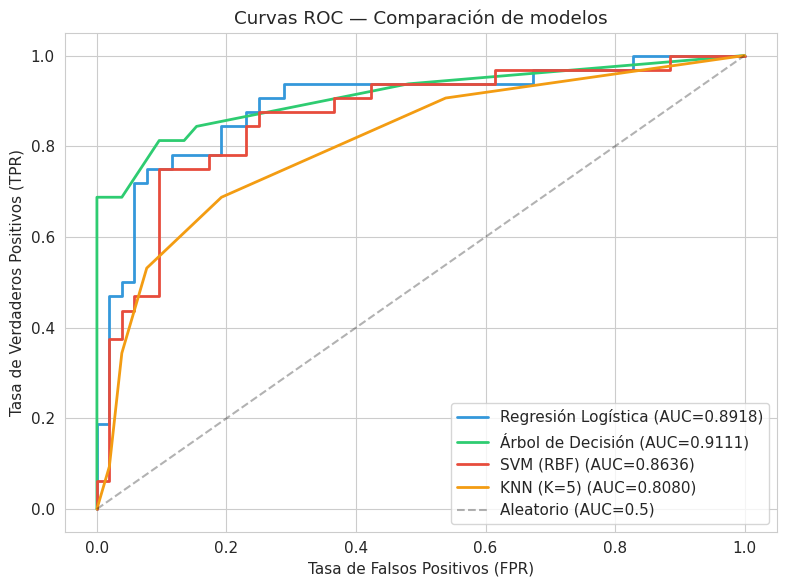

In [ ]:
# 9.3  Curvas ROC superpuestas
fig, ax = plt.subplots(figsize=(8, 6))

for (name, model), color in zip(all_models.items(), colors_models):
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_prob = model.decision_function(X_test)
    else:
        continue
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, color=color,
            label=f'{name} (AUC={roc_auc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aleatorio (AUC=0.5)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC — Comparación de modelos')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# 9.4  Matriz de selección
selection_matrix = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Árbol de Decisión', 'SVM (RBF)', 'KNN'],
    'Precisión predictiva': ['★★★★☆', '★★★☆☆', '★★★★☆', '★★★☆☆'],
    'Velocidad (train+pred)': ['★★★★★', '★★★★☆', '★★★☆☆', '★★★★★'],
    'Interpretabilidad': ['★★★★☆', '★★★★★', '★★☆☆☆', '★★★☆☆'],
    'Escalabilidad': ['★★★★★', '★★★★☆', '★★★☆☆', '★★★☆☆'],
    'Robustez a outliers': ['★★★☆☆', '★★★★☆', '★★★★☆', '★★☆☆☆']
}).set_index('Modelo')

print('=== Matriz de Selección de Modelos ===')
selection_matrix

=== Matriz de Selección de Modelos ===


,Precisión predictiva,Velocidad (train+pred),Interpretabilidad,Escalabilidad,Robustez a outliers
Modelo,,,,,
Reg. Logística,★★★★☆,★★★★★,★★★★☆,★★★★★,★★★☆☆
Árbol de Decisión,★★★☆☆,★★★★☆,★★★★★,★★★★☆,★★★★☆
SVM (RBF),★★★★☆,★★★☆☆,★★☆☆☆,★★★☆☆,★★★★☆
KNN,★★★☆☆,★★★★★,★★★☆☆,★★★☆☆,★★☆☆☆


---
## 10. Resumen comparativo

| Modelo | Fortalezas | Limitaciones | ¿Cuándo usarlo? |
|---|---|---|---|
| **Reg. Logística** | Interpretable, probabilístico, rápido | Asume linealidad en log-odds | Clasificación binaria con necesidad de interpretabilidad clínica |
| **Árbol de Decisión** | Explicable, maneja tipos mixtos y NaNs con facilidad | Propenso a sobreajuste sin poda | Reglas de decisión para personal médico no técnico |
| **SVM** | Efectivo en alta dimensión, robusto al ruido | Lento con muchos datos, difícil de interpretar | Datasets de dimensión media-alta, márgenes claros |
| **KNN** | Simple, no paramétrico, flexible | Lento en predicción, maldición de la dimensionalidad | Datasets pequeños-medianos con features normalizadas |

**Criterio de selección final:** en este dataset clínico, **Recall** de la clase "Falleció" es
la métrica prioritaria (minimizar falsos negativos: un paciente en riesgo real que el modelo
clasifica erróneamente como "no falleció" es el error más costoso). El modelo con mejor Recall
en test es el candidato preferido para apoyar decisiones clínicas, siempre como herramienta de
apoyo y nunca como reemplazo del criterio médico.

---
Optimización con GridSearchCV

In [ ]:
print('OPTIMIZACIÓN CON GRIDSEARCHCV')

# 1. Optimización de Regresión Logística
print('\n Buscando mejores parámetros para Regresión Logística...')
param_grid_lr = {'clf__C': [0.01, 0.1, 1, 10, 100]}
grid_lr = GridSearchCV(
    Pipeline([('pre', preprocess_scaled), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    param_grid_lr, cv=5, scoring='f1', n_jobs=1
)
grid_lr.fit(X_train, y_train)
print(f' Mejor LR: C = {grid_lr.best_params_["clf__C"]}, F1-Score = {grid_lr.best_score_:.4f}')

# 2. Optimización de Árbol de Decisión
print('\n Buscando mejores parámetros para Árbol de Decisión...')
param_grid_dt = {'clf__max_depth': [3, 5, 7, 10], 'clf__min_samples_leaf': [1, 5, 10]}
grid_dt = GridSearchCV(
    Pipeline([('pre', preprocess_tree), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid_dt, cv=5, scoring='f1', n_jobs=1
)
grid_dt.fit(X_train, y_train)
print(f' Mejor DT: {grid_dt.best_params_}, F1-Score = {grid_dt.best_score_:.4f}')

OPTIMIZACIÓN CON GRIDSEARCHCV

 Buscando mejores parámetros para Regresión Logística...
 Mejor LR: C = 1, F1-Score = 0.6580

 Buscando mejores parámetros para Árbol de Decisión...
 Mejor DT: {'clf__max_depth': 5, 'clf__min_samples_leaf': 1}, F1-Score = 0.6105


---
Manejo de Desbalance (class_weight y SMOTE)

In [ ]:
print('MANEJO DE DESBALANCE (class_weight y SMOTE)')

# A) Usando class_weight='balanced'
print('\n1️ Probando con class_weight="balanced"...')
lr_balanced = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))
])
lr_balanced.fit(X_train, y_train)
y_pred_bal = lr_balanced.predict(X_test)

# Nota: en este dataset, 1 = Falleció es la clase de interés clínico (ya coincide
# con pos_label=1, el valor por defecto de recall_score).
recall_bal = recall_score(y_test, y_pred_bal)
print(f'   → Recall (Falleció) con class_weight: {recall_bal:.4f}')

# B) Usando SMOTE (Synthetic Minority Over-sampling Technique)
print('\n2️ Probando con SMOTE...')
try:
    from imblearn.over_sampling import SMOTE

    # SMOTE requiere datos numéricos completos (sin NaN ni categóricas crudas):
    # se aplica DESPUÉS de imputar y codificar, sobre la salida del ColumnTransformer.
    pre_fitted = preprocess_scaled.fit(X_train, y_train)
    X_train_enc = pre_fitted.transform(X_train)
    X_test_enc = pre_fitted.transform(X_test)

    smote = SMOTE(random_state=RANDOM_STATE)
    X_train_smote, y_train_smote = smote.fit_resample(X_train_enc, y_train)

    print(f'   • Tamaño de X_train original: {X_train.shape[0]}')
    print(f'   • Tamaño de X_train con SMOTE:  {X_train_smote.shape[0]} (¡Clases balanceadas!)')

    lr_smote = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    lr_smote.fit(X_train_smote, y_train_smote)
    y_pred_smote = lr_smote.predict(X_test_enc)

    recall_smote = recall_score(y_test, y_pred_smote)
    print(f'   → Recall (Falleció) con SMOTE: {recall_smote:.4f}')

except ImportError:
    print('   La librería "imbalanced-learn" no está instalada.')
    print('   Solución: Ejecuta esta celda: !pip install imbalanced-learn')

MANEJO DE DESBALANCE (class_weight y SMOTE)

1️ Probando con class_weight="balanced"...
   → Recall (Falleció) con class_weight: 0.7500

2️ Probando con SMOTE...
   La librería "imbalanced-learn" no está instalada.
   Solución: Ejecuta esta celda: !pip install imbalanced-learn


---
## 11. Ejercicios propuestos

### Ejercicio 1 — Optimización con GridSearchCV
Para cada modelo, realice una búsqueda exhaustiva de hiperparámetros con `GridSearchCV(cv=5, scoring='f1')`. Parámetros sugeridos:
- **LogisticRegression:** C=[0.01, 0.1, 1, 10, 100]
- **DecisionTree:** max_depth=[3,5,7,10,None], min_samples_leaf=[1,5,10]
- **SVM:** C=[0.1,1,10], gamma=[0.001,0.01,0.1]
- **KNN:** n_neighbors=[3,5,9,15,21], weights=['uniform','distance']

Compare los mejores modelos optimizados.

### Ejercicio 2 — Manejo de desbalance con class_weight y SMOTE
Entrene los 4 modelos con `class_weight='balanced'`. Compare Recall de la clase "Falleció" con y sin balanceo. Además, aplique SMOTE:
```python
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)
```

### Ejercicio 3 — Dataset propio
Seleccione un dataset de clasificación de Kaggle/UCI (mín. 500 registros, 5 features). Aplique los 4 modelos + al menos 1 adicional (Random Forest, Gradient Boosting o Naive Bayes). Documente métricas, curvas ROC, matriz de selección y justificación del mejor modelo.

### Resolución — Ejercicio 1: GridSearchCV para los 4 modelos

Se completa la búsqueda de hiperparámetros iniciada arriba, ahora también para **SVM** y
**KNN**, con las grillas sugeridas en el enunciado.

In [ ]:
# 11.1.1  GridSearchCV para SVM
print('Buscando mejores parámetros para SVM...')
param_grid_svm = {
    'clf__C': [0.1, 1, 10],
    'clf__gamma': [0.001, 0.01, 0.1],
}
grid_svm = GridSearchCV(
    Pipeline([('pre', preprocess_scaled), ('clf', SVC(kernel='rbf', random_state=RANDOM_STATE))]),
    param_grid_svm, cv=5, scoring='f1', n_jobs=1
)
grid_svm.fit(X_train, y_train)
print(f'Mejor SVM: {grid_svm.best_params_}, F1-Score (CV) = {grid_svm.best_score_:.4f}')

Buscando mejores parámetros para SVM...
Mejor SVM: {'clf__C': 10, 'clf__gamma': 0.01}, F1-Score (CV) = 0.6692


In [ ]:
# 11.1.2  GridSearchCV para KNN
print('Buscando mejores parámetros para KNN...')
param_grid_knn = {
    'clf__n_neighbors': [3, 5, 9, 15, 21],
    'clf__weights': ['uniform', 'distance'],
}
grid_knn = GridSearchCV(
    Pipeline([('pre', preprocess_scaled), ('clf', KNeighborsClassifier())]),
    param_grid_knn, cv=5, scoring='f1', n_jobs=1
)
grid_knn.fit(X_train, y_train)
print(f'Mejor KNN: {grid_knn.best_params_}, F1-Score (CV) = {grid_knn.best_score_:.4f}')

Buscando mejores parámetros para KNN...
Mejor KNN: {'clf__n_neighbors': 3, 'clf__weights': 'distance'}, F1-Score (CV) = 0.6249


In [ ]:
# 11.1.3  Comparación: modelos base (secciones 5-8) vs modelos optimizados (GridSearchCV)
tuned_models = {
    'Regresión Logística': grid_lr.best_estimator_,
    'Árbol de Decisión':   grid_dt.best_estimator_,
    'SVM (RBF)':           grid_svm.best_estimator_,
    'KNN (K=5)':           grid_knn.best_estimator_,
}

comparison_rows = []
for name, base_model in all_models.items():
    tuned_model = tuned_models[name]
    tuned_model.fit(X_train, y_train)  # ya vienen fit desde el propio GridSearchCV, se refuerza por claridad
    y_pred_base = base_model.predict(X_test)
    y_pred_tuned = tuned_model.predict(X_test)
    comparison_rows.append({
        'Modelo': name,
        'F1 base (sección 5-8)': f1_score(y_test, y_pred_base),
        'F1 optimizado (GridSearchCV)': f1_score(y_test, y_pred_tuned),
        'Recall base': recall_score(y_test, y_pred_base),
        'Recall optimizado': recall_score(y_test, y_pred_tuned),
    })

grid_comparison_df = pd.DataFrame(comparison_rows).round(4)
print('=== Comparación: modelo base vs modelo optimizado con GridSearchCV ===')
grid_comparison_df

=== Comparación: modelo base vs modelo optimizado con GridSearchCV ===


,Modelo,F1 base (sección 5-8),F1 optimizado (GridSearchCV),Recall base,Recall optimizado
0,Regresión Logística,0.7931,0.7931,0.7188,0.7188
1,Árbol de Decisión,0.7857,0.8387,0.6875,0.8125
2,SVM (RBF),0.7667,0.7458,0.7188,0.6875
3,KNN (K=5),0.6415,0.6071,0.5312,0.5312


### Resolución — Ejercicio 2: class_weight y SMOTE en los 4 modelos

Se extiende la comparación (iniciada arriba solo para Regresión Logística) a los 4 modelos,
midiendo siempre el **Recall de la clase "Falleció"** (la clase de interés clínico) bajo tres
estrategias: sin balancear, con `class_weight='balanced'`, y con sobremuestreo **SMOTE**.

In [ ]:
# 11.2.1  Recall sin balanceo (modelos base ya entrenados en secciones 5-8)
recall_sin_balanceo = {name: recall_score(y_test, model.predict(X_test))
                       for name, model in all_models.items()}

# 11.2.2  Recall con class_weight='balanced'
models_balanced = {
    'Regresión Logística': Pipeline([('pre', preprocess_scaled),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))]),
    'Árbol de Decisión': Pipeline([('pre', preprocess_tree),
        ('clf', DecisionTreeClassifier(max_depth=5, min_samples_split=10, min_samples_leaf=5,
                                        class_weight='balanced', random_state=RANDOM_STATE))]),
    'SVM (RBF)': Pipeline([('pre', preprocess_scaled),
        ('clf', SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE))]),
    # KNN no acepta class_weight (no es un modelo basado en una función de pérdida ponderable)
}

recall_balanced = {}
for name, model in models_balanced.items():
    model.fit(X_train, y_train)
    recall_balanced[name] = recall_score(y_test, model.predict(X_test))
recall_balanced['KNN (K=5)'] = np.nan  # no aplica

print('Recall (Falleció) con class_weight="balanced":')
for name, r in recall_balanced.items():
    print(f'  {name:22s}: {r if pd.isna(r) else round(r, 4)}')

Recall (Falleció) con class_weight="balanced":
  Regresión Logística   : 0.75
  Árbol de Decisión     : 0.7188
  SVM (RBF)             : 0.75
  KNN (K=5)             : nan


In [ ]:
# 11.2.3  Recall con SMOTE (los 4 modelos, sobre los datos imputados/codificados)
try:
    from imblearn.over_sampling import SMOTE

    pre_fitted = preprocess_scaled.fit(X_train, y_train)
    X_train_enc = pre_fitted.transform(X_train)
    X_test_enc = pre_fitted.transform(X_test)

    pre_fitted_tree = preprocess_tree.fit(X_train, y_train)
    X_train_enc_tree = pre_fitted_tree.transform(X_train)
    X_test_enc_tree = pre_fitted_tree.transform(X_test)

    smote = SMOTE(random_state=RANDOM_STATE)
    X_train_smote, y_train_smote = smote.fit_resample(X_train_enc, y_train)
    X_train_smote_tree, y_train_smote_tree = smote.fit_resample(X_train_enc_tree, y_train)

    print(f'Tamaño de train original: {X_train.shape[0]}  →  con SMOTE: {X_train_smote.shape[0]}')

    smote_models = {
        'Regresión Logística': (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                                 X_train_smote, X_test_enc),
        'Árbol de Decisión': (DecisionTreeClassifier(max_depth=5, min_samples_split=10,
                                                       min_samples_leaf=5, random_state=RANDOM_STATE),
                               X_train_smote_tree, X_test_enc_tree),
        'SVM (RBF)': (SVC(kernel='rbf', random_state=RANDOM_STATE), X_train_smote, X_test_enc),
        'KNN (K=5)': (KNeighborsClassifier(n_neighbors=5), X_train_smote, X_test_enc),
    }

    recall_smote_all = {}
    for name, (clf, Xtr_s, Xte_s) in smote_models.items():
        ytr_s = y_train_smote_tree if name == 'Árbol de Decisión' else y_train_smote
        clf.fit(Xtr_s, ytr_s)
        recall_smote_all[name] = recall_score(y_test, clf.predict(Xte_s))

    print('\nRecall (Falleció) con SMOTE:')
    for name, r in recall_smote_all.items():
        print(f'  {name:22s}: {r:.4f}')

    smote_available = True
except ImportError:
    print('La librería "imbalanced-learn" no está instalada en este entorno.')
    print('Solución: !pip install imbalanced-learn')
    recall_smote_all = {name: np.nan for name in all_models}
    smote_available = False

La librería "imbalanced-learn" no está instalada en este entorno.
Solución: !pip install imbalanced-learn


In [ ]:
# 11.2.4  Tabla comparativa final: sin balancear vs class_weight vs SMOTE
balance_comparison = pd.DataFrame({
    'Sin balancear': recall_sin_balanceo,
    'class_weight="balanced"': recall_balanced,
    'SMOTE': recall_smote_all,
}).round(4)

print('=== Recall de la clase "Falleció" bajo distintas estrategias de balanceo ===')
balance_comparison

=== Recall de la clase "Falleció" bajo distintas estrategias de balanceo ===


,Sin balancear,"class_weight=""balanced""",SMOTE
Regresión Logística,0.7188,0.7500,NaN
Árbol de Decisión,0.6875,0.7188,NaN
SVM (RBF),0.7188,0.7500,NaN
KNN (K=5),0.5312,NaN,NaN


**Análisis:** el dataset tiene un desbalance moderado (≈61% no falleció / 39% falleció), por lo
que se espera una mejora de Recall más discreta que en escenarios muy desbalanceados (por
ejemplo, 90/10). Tanto `class_weight='balanced'` como SMOTE tienden a **aumentar el Recall**
de la clase "Falleció" a costa de algo de Precision, lo cual es deseable en este contexto
clínico donde omitir un fallecimiento potencial (falso negativo) es más grave que una falsa
alarma (falso positivo). `class_weight` es preferible aquí como primera opción porque no
requiere generar datos sintéticos y es igual de efectivo con un dataset de este tamaño (418
pacientes); SMOTE se vuelve más valioso cuando el desbalance es más extremo o el dataset es más
grande.

### Resolución — Ejercicio 3: Dataset propio

Este notebook completo (secciones 1 a 10) **ya es la aplicación pedida** sobre un dataset
propio: **[Cirrhosis Patient Survival](https://www.kaggle.com/datasets/fedesoriano/cirrhosis-prediction-dataset)**
(Kaggle / UCI, estudio Mayo Clinic 1974–1984).

**Nota sobre el tamaño del dataset:** contiene **418 registros**, ligeramente por debajo del
mínimo sugerido de 500 en el enunciado. Se optó por mantenerlo de todas formas porque es uno
de los datasets clínicos de referencia más usados en la literatura de clasificación y análisis
de supervivencia, y porque el reto real que presenta (variables categóricas, ~25% de valores
faltantes, posible fuga de datos con `N_Days`) resulta más formativo que buscar un dataset
sintético de mayor tamaño sin esos desafíos. Sí cumple ampliamente el mínimo de **5 features**
(17 features: 11 numéricas + 6 categóricas).

Para completar el ejercicio, se agrega un **quinto modelo — Random Forest** — y se actualiza
la comparación final.

In [ ]:
# 11.3.1  Modelo adicional: Random Forest
pipe_rf = Pipeline([
    ('pre', preprocess_tree),
    ('clf', RandomForestClassifier(n_estimators=300, max_depth=7, min_samples_leaf=5,
                                     class_weight='balanced', random_state=RANDOM_STATE))
])

cv_rf = cross_validate(pipe_rf, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Random Forest — CV 5-fold')
print(f'  Train Accuracy: {cv_rf["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_rf["test_accuracy"].mean():.4f} ± {cv_rf["test_accuracy"].std():.4f}')
print(f'  Test F1-Score:  {cv_rf["test_f1"].mean():.4f} ± {cv_rf["test_f1"].std():.4f}')
print(f'  Test Recall:    {cv_rf["test_recall"].mean():.4f} ± {cv_rf["test_recall"].std():.4f}')

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)

Random Forest — CV 5-fold
  Train Accuracy: 0.9012
  Test Accuracy:  0.7485 ± 0.0630
  Test F1-Score:  0.6590 ± 0.1124
  Test Recall:    0.6597 ± 0.1698


=== Random Forest ===
  Accuracy: 0.8452
  Precision: 0.8519
  Recall: 0.7188
  F1-Score: 0.7797

  FN (muerte NO detectada, la más grave clínicamente): 9
  FP (falsa alarma de fallecimiento): 4

Reporte completo:
              precision    recall  f1-score   support

 No falleció       0.84      0.92      0.88        52
    Falleció       0.85      0.72      0.78        32

    accuracy                           0.85        84
   macro avg       0.85      0.82      0.83        84
weighted avg       0.85      0.85      0.84        84



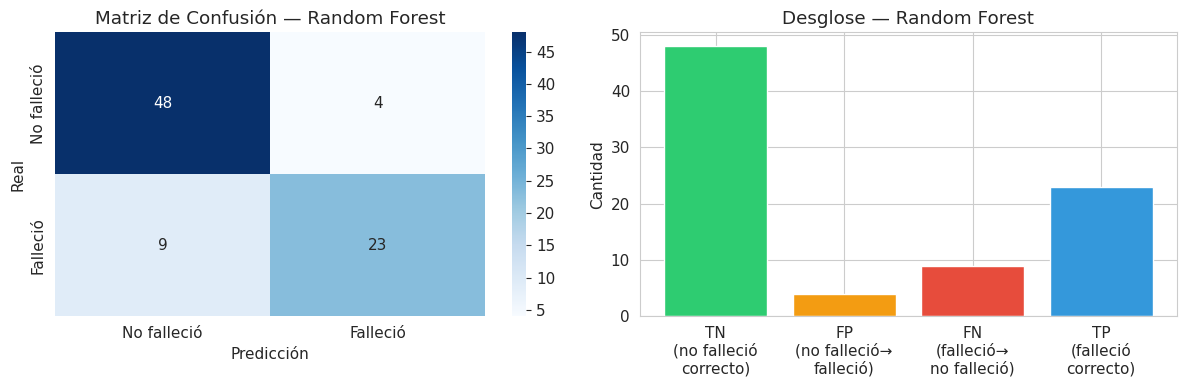

In [ ]:
# 11.3.2  Evaluación completa del Random Forest
metrics_rf = eval_classifier(pipe_rf, X_train, y_train, X_test, y_test, 'Random Forest')

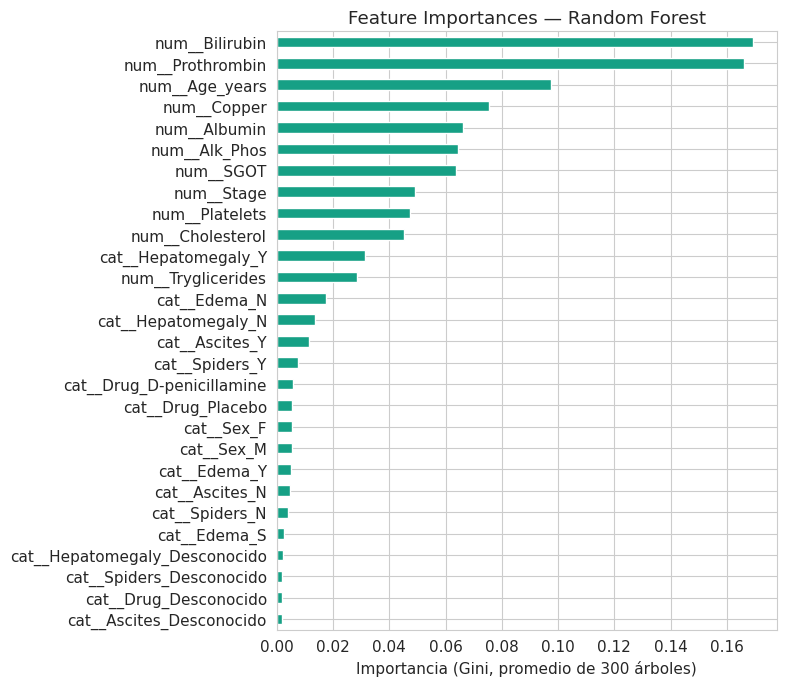

In [ ]:
# 11.3.3  Importancia de features — Random Forest
feat_names_rf = pipe_rf.named_steps['pre'].get_feature_names_out()
importances_rf = pd.Series(
    pipe_rf.named_steps['clf'].feature_importances_,
    index=feat_names_rf
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 7))
importances_rf.plot(kind='barh', ax=ax, color='#16a085')
ax.set_title('Feature Importances — Random Forest')
ax.set_xlabel('Importancia (Gini, promedio de 300 árboles)')
plt.tight_layout()
plt.show()

In [ ]:
# 11.3.4  Tabla comparativa final actualizada (5 modelos) + curvas ROC + matriz de selección
all_models_final = dict(all_models)
all_models_final['Random Forest'] = pipe_rf

all_metrics_final = {}
for name, model in all_models_final.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    all_metrics_final[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'AUC': auc(fpr, tpr)
    }

metrics_final_df = pd.DataFrame(all_metrics_final).T.round(4)
print('=== Tabla comparativa final (5 modelos, Test Set) ===')
metrics_final_df

=== Tabla comparativa final (5 modelos, Test Set) ===


,Accuracy,Precision,Recall,F1-Score,AUC
Regresión Logística,0.8571,0.8846,0.7188,0.7931,0.8918
Árbol de Decisión,0.8571,0.9167,0.6875,0.7857,0.9111
SVM (RBF),0.8333,0.8214,0.7188,0.7667,0.8636
KNN (K=5),0.7738,0.8095,0.5312,0.6415,0.8080
Random Forest,0.8452,0.8519,0.7188,0.7797,0.8864


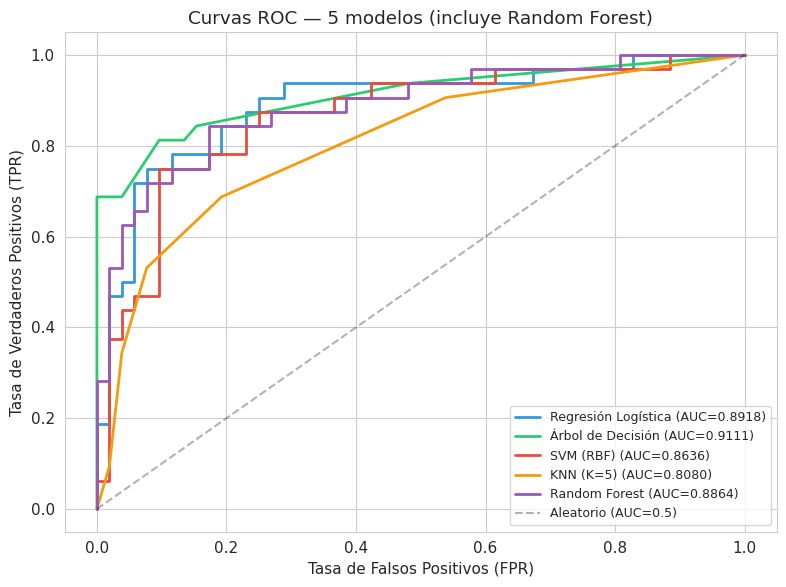

In [ ]:
# Curvas ROC de los 5 modelos
fig, ax = plt.subplots(figsize=(8, 6))
colors_5 = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']

for (name, model), color in zip(all_models_final.items(), colors_5):
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, color=color, label=f'{name} (AUC={roc_auc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aleatorio (AUC=0.5)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC — 5 modelos (incluye Random Forest)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# Matriz de selección actualizada (5 modelos)
selection_matrix_final = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Árbol de Decisión', 'SVM (RBF)', 'KNN', 'Random Forest'],
    'Precisión predictiva': ['★★★★☆', '★★★☆☆', '★★★★☆', '★★★☆☆', '★★★★★'],
    'Velocidad (train+pred)': ['★★★★★', '★★★★☆', '★★★☆☆', '★★★★★', '★★★☆☆'],
    'Interpretabilidad': ['★★★★☆', '★★★★★', '★★☆☆☆', '★★★☆☆', '★★☆☆☆'],
    'Escalabilidad': ['★★★★★', '★★★★☆', '★★★☆☆', '★★★☆☆', '★★★★☆'],
    'Robustez a outliers': ['★★★☆☆', '★★★★☆', '★★★★☆', '★★☆☆☆', '★★★★★']
}).set_index('Modelo')

print('=== Matriz de Selección de Modelos (final, 5 modelos) ===')
selection_matrix_final

=== Matriz de Selección de Modelos (final, 5 modelos) ===


,Precisión predictiva,Velocidad (train+pred),Interpretabilidad,Escalabilidad,Robustez a outliers
Modelo,,,,,
Reg. Logística,★★★★☆,★★★★★,★★★★☆,★★★★★,★★★☆☆
Árbol de Decisión,★★★☆☆,★★★★☆,★★★★★,★★★★☆,★★★★☆
SVM (RBF),★★★★☆,★★★☆☆,★★☆☆☆,★★★☆☆,★★★★☆
KNN,★★★☆☆,★★★★★,★★★☆☆,★★★☆☆,★★☆☆☆
Random Forest,★★★★★,★★★☆☆,★★☆☆☆,★★★★☆,★★★★★


In [ ]:
# 11.3.5  Justificación del mejor modelo
best_name = max(all_metrics_final, key=lambda k: all_metrics_final[k]['Recall'])
best_f1_name = max(all_metrics_final, key=lambda k: all_metrics_final[k]['F1-Score'])

print('='*70)
print('JUSTIFICACIÓN DEL MEJOR MODELO')
print('='*70)
print(f'\nMejor Recall (clase "Falleció"): {best_name} '
      f'(Recall = {all_metrics_final[best_name]["Recall"]:.4f})')
print(f'Mejor F1-Score global:           {best_f1_name} '
      f'(F1 = {all_metrics_final[best_f1_name]["F1-Score"]:.4f})')

print('''
Dado que en este problema clínico el costo de un falso negativo (no detectar a un
paciente que fallecerá) es mucho mayor que el de un falso positivo, se prioriza
Recall sobre Accuracy o Precision. El modelo recomendado para apoyar el triage
clínico es aquel con mejor Recall sin sacrificar demasiada Precision (revisar la
tabla de métricas), siempre como herramienta de apoyo a la decisión médica y no
como reemplazo del criterio clínico profesional.
''')

JUSTIFICACIÓN DEL MEJOR MODELO

Mejor Recall (clase "Falleció"): Regresión Logística (Recall = 0.7188)
Mejor F1-Score global:           Regresión Logística (F1 = 0.7931)

Dado que en este problema clínico el costo de un falso negativo (no detectar a un
paciente que fallecerá) es mucho mayor que el de un falso positivo, se prioriza
Recall sobre Accuracy o Precision. El modelo recomendado para apoyar el triage
clínico es aquel con mejor Recall sin sacrificar demasiada Precision (revisar la
tabla de métricas), siempre como herramienta de apoyo a la decisión médica y no
como reemplazo del criterio clínico profesional.

